# KKBox Churn Features — Manual Segment EDA

Identical analysis to `KKBox_Correlation_Churn.ipynb`, but restricted to the
**`state='manual'`** segment: users whose last payment was **not** auto-renewal
and whose last transaction day was not a cancel-only day.

In the February cohort the manual segment contains ~110,846 users (11.2%)
with a **31.78% churn rate** vs 6.39% for the full cohort — a qualitatively
different population where churn is much more common.

Some features that are constant or near-constant for the full cohort (e.g.
`autorenew_not_cancel`) may become informative here, and vice versa.

## 0. Paths and subscription state

In [1]:
import sys
import json
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from datetime import date
from pathlib import Path

# Walk up from CWD to find the workshops/ root
HERE = Path.cwd().resolve()
EDA_DIR = DATA_DIR = None
for _p in [HERE, *HERE.parents]:
    if (_p / 'eda' / '_common.py').exists():
        EDA_DIR  = _p / 'eda'
        DATA_DIR = _p / 'w1' / 'export-tabular-v5'
        STATE_PATH = _p / 'w1' / 'artifacts' / 'sherlock_w1' / 'preprocessing' / 'development.json'
        break
if EDA_DIR is None:
    raise FileNotFoundError('Cannot find workshops/eda/_common.py')

sys.path.insert(0, str(EDA_DIR))
import _common as C

COHORT      = 'train_feb'
FEB_CUTOFF  = date(2017, 1, 31)
GRAPHICS_DIR = DATA_DIR.parent / 'figures' / 'eda_manual'
GRAPHICS_DIR.mkdir(parents=True, exist_ok=True)

print(f'DATA_DIR:     {DATA_DIR}')
print(f'EDA_DIR:      {EDA_DIR}')
print(f'GRAPHICS_DIR: {GRAPHICS_DIR}')

DATA_DIR:     C:\Users\Usuario\Desktop\Materias\ML\Final Project\workshops\w1\export-tabular-v5
EDA_DIR:      C:\Users\Usuario\Desktop\Materias\ML\Final Project\workshops\eda
GRAPHICS_DIR: C:\Users\Usuario\Desktop\Materias\ML\Final Project\workshops\w1\figures\eda_manual


In [2]:
# Compute subscription state for every February user via _common.py
C.set_cutoff(FEB_CUTOFF)
cohort   = C.load_cohort()                       # msno, is_churn, split
_users   = cohort.select('msno', 'is_churn')
txn_feb  = C.clean_transactions(_users)
state_feb = C.subscription_state(txn_feb, _users) # adds state, days_to_expire, …

state_map = dict(zip(state_feb['msno'].to_list(), state_feb['state'].to_list()))

n_manual = sum(v == 'manual' for v in state_map.values())
print(f'Feb users: {len(state_map):,} total | {n_manual:,} manual ({n_manual/len(state_map):.1%})')

Feb users: 992,931 total | 110,846 manual (11.2%)


## 1. Load parquet — manual segment only

In [3]:
# Load features catalogue
state_path = STATE_PATH if STATE_PATH.exists() else DATA_DIR / 'metadata.json'
state = json.loads(state_path.read_text())
FEATURES    = state['features']
CATEGORICAL = state['categorical']

# Load full parquet, attach state, filter to manual
df_full = pd.read_parquet(DATA_DIR / f'{COHORT}.parquet', columns=['msno', 'is_churn'] + FEATURES)
df_full['state'] = df_full['msno'].map(state_map)
df = df_full[df_full['state'] == 'manual'].drop(columns=['state']).reset_index(drop=True)

assert df['msno'].is_unique, 'expected one row per customer'
y = df['is_churn'].astype(int)

print(f'Full Feb cohort: {len(df_full):,} | manual segment: {len(df):,} ({len(df)/len(df_full):.1%})')
print(f'Churn rate — full: {df_full["is_churn"].mean():.2%} | manual: {y.mean():.2%}')
display(df.head())

Full Feb cohort: 992,931 | manual segment: 110,846 (11.2%)
Churn rate — full: 6.39% | manual: 31.78%


,msno,is_churn,city,registered_via,bd,bd_missing,tenure_days,registration_year,registration_month,has_member_record,...,last_third_sum_total_songs,last_third_ratio_100,last_third_ratio_25,login_difference,trend_songs,trend_secs,trend_ratio100,trend_ratio25,days_since_last_log,has_listening_logs
0,waLDQMmcOu2jLDaV1ddDkgCrB/jl6sD66Xzs0Vqax1Y=,1,18.0,9,36.0,0,4318.0,2005.0,4.0,1,...,0,0.000000,0.000000,16,15.461538,19.026041,0.020896,-0.032935,2,1
1,mT5V8rEpa+8wuqi6x0DoVd3H5icMKkE9Prt49UlmK+4=,1,13.0,9,23.0,0,4108.0,2005.0,11.0,1,...,1658,0.578408,0.212907,-1,0.892241,0.924839,0.036639,-0.027139,1,1
2,XaPhtGLk/5UvvOYHcONTwsnH97P4eGECeq+BARGItRw=,1,3.0,9,27.0,0,4052.0,2005.0,12.0,1,...,3059,0.978424,0.004577,-4,0.555601,0.544287,-0.020418,0.001882,1,1
3,lYLh7TdkWpIoQs3i3o6mIjLH8/IEgMWP9r7OpsLX0Vo=,1,13.0,9,29.0,0,3953.0,2006.0,4.0,1,...,134,0.910448,0.074627,-2,1.324241,1.336228,0.021517,-0.012747,0,1
4,T0FF6lumjKcqEO0O+tUH2ytc+Kb9EkeaLzcVUiTr1aE=,1,11.0,9,22.0,0,3934.0,2006.0,4.0,1,...,1562,0.650448,0.244558,-10,0.610124,0.628636,0.019287,-0.045222,0,1


## 2. Feature catalogue

Same classification logic as the full-cohort notebook, but types are recomputed on
the manual segment — constants may differ (e.g. `autorenew_not_cancel` is always 0
for manual users).

In [4]:
DOMAIN_STARTS = {'member': 'city', 'transactions': 'is_cancel_change_flag', 'logs': 'sum_last_month_unq'}
starts = sorted((FEATURES.index(first), name) for name, first in DOMAIN_STARTS.items())
DOMAIN = {}
for (start, name), (end, _) in zip(starts, starts[1:] + [(len(FEATURES), None)]):
    DOMAIN.update({feature: name for feature in FEATURES[start:end]})


def feature_type(series, name):
    values = series.dropna()
    n_unique = values.nunique()
    if name in CATEGORICAL:
        return 'categorical'
    if n_unique <= 1:
        return 'constant'
    if n_unique == 2:
        return 'binary'
    if n_unique <= 31 and np.allclose(values, np.round(values)):
        return 'discrete'
    return 'continuous'


catalogue = pd.DataFrame({
    'domain':      [DOMAIN[f] for f in FEATURES],
    'type':        [feature_type(df[f], f) for f in FEATURES],
    'dtype':       [str(df[f].dtype) for f in FEATURES],
    'n_unique':    [df[f].nunique() for f in FEATURES],
    'missing_pct': [df[f].isna().mean() * 100 for f in FEATURES],
}, index=pd.Index(FEATURES, name='feature'))

TYPES = {kind: catalogue.index[catalogue['type'].eq(kind)].tolist()
         for kind in ['categorical', 'binary', 'discrete', 'continuous', 'constant']}
NUMERIC = TYPES['binary'] + TYPES['discrete'] + TYPES['continuous']

display(pd.crosstab(catalogue['domain'], catalogue['type'], margins=True))
display(catalogue.round(2))
if TYPES['constant']:
    print('Constant features (no information about churn):', TYPES['constant'])

type,binary,categorical,constant,continuous,discrete,All
domain,,,,,,
logs,1,0,0,21,0,22
member,2,2,0,2,2,8
transactions,3,1,4,14,7,29
All,6,3,4,37,9,59


,domain,type,dtype,n_unique,missing_pct
feature,,,,,
city,member,categorical,float64,21,0.28
registered_via,member,categorical,int16,5,0.00
bd,member,continuous,float32,98,0.00
bd_missing,member,binary,int8,2,0.00
tenure_days,member,continuous,float64,4544,0.28
registration_year,member,discrete,float64,14,0.28
registration_month,member,discrete,float64,12,0.28
has_member_record,member,binary,int8,2,0.00
is_cancel_change_flag,transactions,binary,float64,2,0.00


Constant features (no information about churn): ['autorenew_not_cancel', 'not_autorenew_cancel', 'last_is_cancel', 'has_transactions']


## 3. Target distribution

,customers,percent
is_churn,,
No,75622,68.22
Yes,35224,31.78


Imbalance ratio: 2.15:1 | churn rate: 31.78%


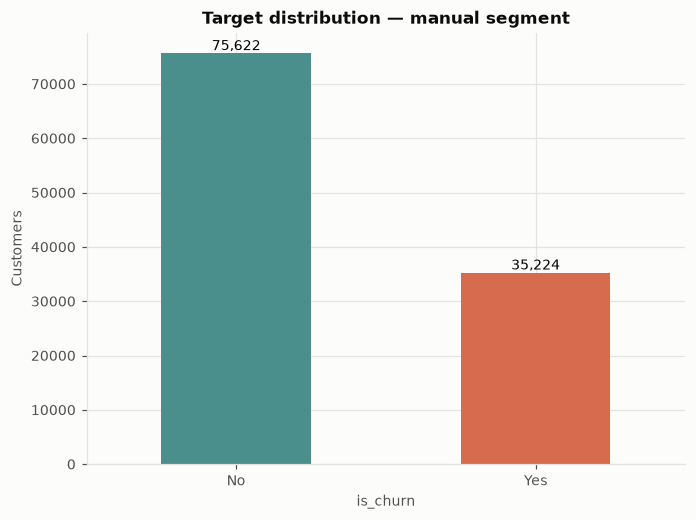

In [5]:
churn_labels = ['No', 'Yes']
churn_colors = ['#4b8f8c', '#d66b4e']

target_counts = y.map({0: 'No', 1: 'Yes'}).value_counts().reindex(churn_labels)
target_pct    = target_counts / len(df) * 100
BASE_RATE     = y.mean()

display(pd.DataFrame({'customers': target_counts, 'percent': target_pct.round(2)}))
print(f'Imbalance ratio: {target_counts.max()/target_counts.min():.2f}:1 | churn rate: {BASE_RATE:.2%}')

ax = target_counts.plot(kind='bar', color=churn_colors, rot=0)
ax.set(title='Target distribution — manual segment', xlabel='is_churn', ylabel='Customers')
ax.bar_label(ax.containers[0], fmt='{:,.0f}')
plt.tight_layout()
plt.savefig(GRAPHICS_DIR / 'target_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

## 4. Numerical feature statistics

In [6]:
summary = df[NUMERIC].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
summary.insert(0, 'type',   catalogue.loc[NUMERIC, 'type'])
summary.insert(0, 'domain', catalogue.loc[NUMERIC, 'domain'])
display(summary.round(3))

,domain,type,count,mean,std,min,1%,25%,50%,75%,99%,max
bd_missing,member,binary,110846.0,0.307,0.461,0.000,0.000,0.000,0.000,1.000,1.000,1.000
has_member_record,member,binary,110846.0,0.997,0.053,0.000,1.000,1.000,1.000,1.000,1.000,1.000
is_cancel_change_flag,transactions,binary,110846.0,0.104,0.306,0.000,0.000,0.000,0.000,0.000,1.000,1.000
is_auto_renew_change_flag,transactions,binary,110846.0,0.106,0.307,0.000,0.000,0.000,0.000,0.000,1.000,1.000
last_is_auto_renew,transactions,binary,110846.0,0.000,0.012,0.000,0.000,0.000,0.000,0.000,0.000,1.000
has_listening_logs,logs,binary,110846.0,0.990,0.098,0.000,1.000,1.000,1.000,1.000,1.000,1.000
registration_year,member,discrete,110536.0,2013.577,2.697,2004.000,2005.000,2013.000,2014.000,2016.000,2017.000,2017.000
registration_month,member,discrete,110536.0,6.686,3.629,1.000,1.000,3.000,7.000,10.000,12.000,12.000
n_payment_methods,transactions,discrete,110846.0,1.522,0.706,1.000,1.000,1.000,1.000,2.000,4.000,7.000
n_plans,transactions,discrete,110846.0,1.626,0.798,1.000,1.000,1.000,1.000,2.000,4.000,7.000


## 5. Correlation of numeric features with churn

Pearson, Spearman, and ROC AUC — same as the full-cohort notebook, but computed
inside the manual segment where churn rate is ~32%.

,domain,type,pearson,spearman,roc_auc
last_login,logs,continuous,-0.2454,-0.2295,0.3578
transaction_count,transactions,continuous,-0.1733,-0.2112,0.3694
last_second_login,logs,continuous,-0.2206,-0.2091,0.3706
last_sum_total_songs,logs,continuous,-0.1432,-0.2066,0.3719
sum_last_month_unq,logs,continuous,-0.1472,-0.2045,0.3732
last_second_sum_total_songs,logs,continuous,-0.1364,-0.2000,0.3761
sum_last_month_total_secs,logs,continuous,-0.1258,-0.1982,0.3771
sum_last_second_month_total_secs,logs,continuous,-0.1190,-0.1927,0.3806
last_third_sum_total_songs,logs,continuous,-0.1267,-0.1839,0.3865
last_plan_days,transactions,discrete,0.1827,0.1590,0.5727


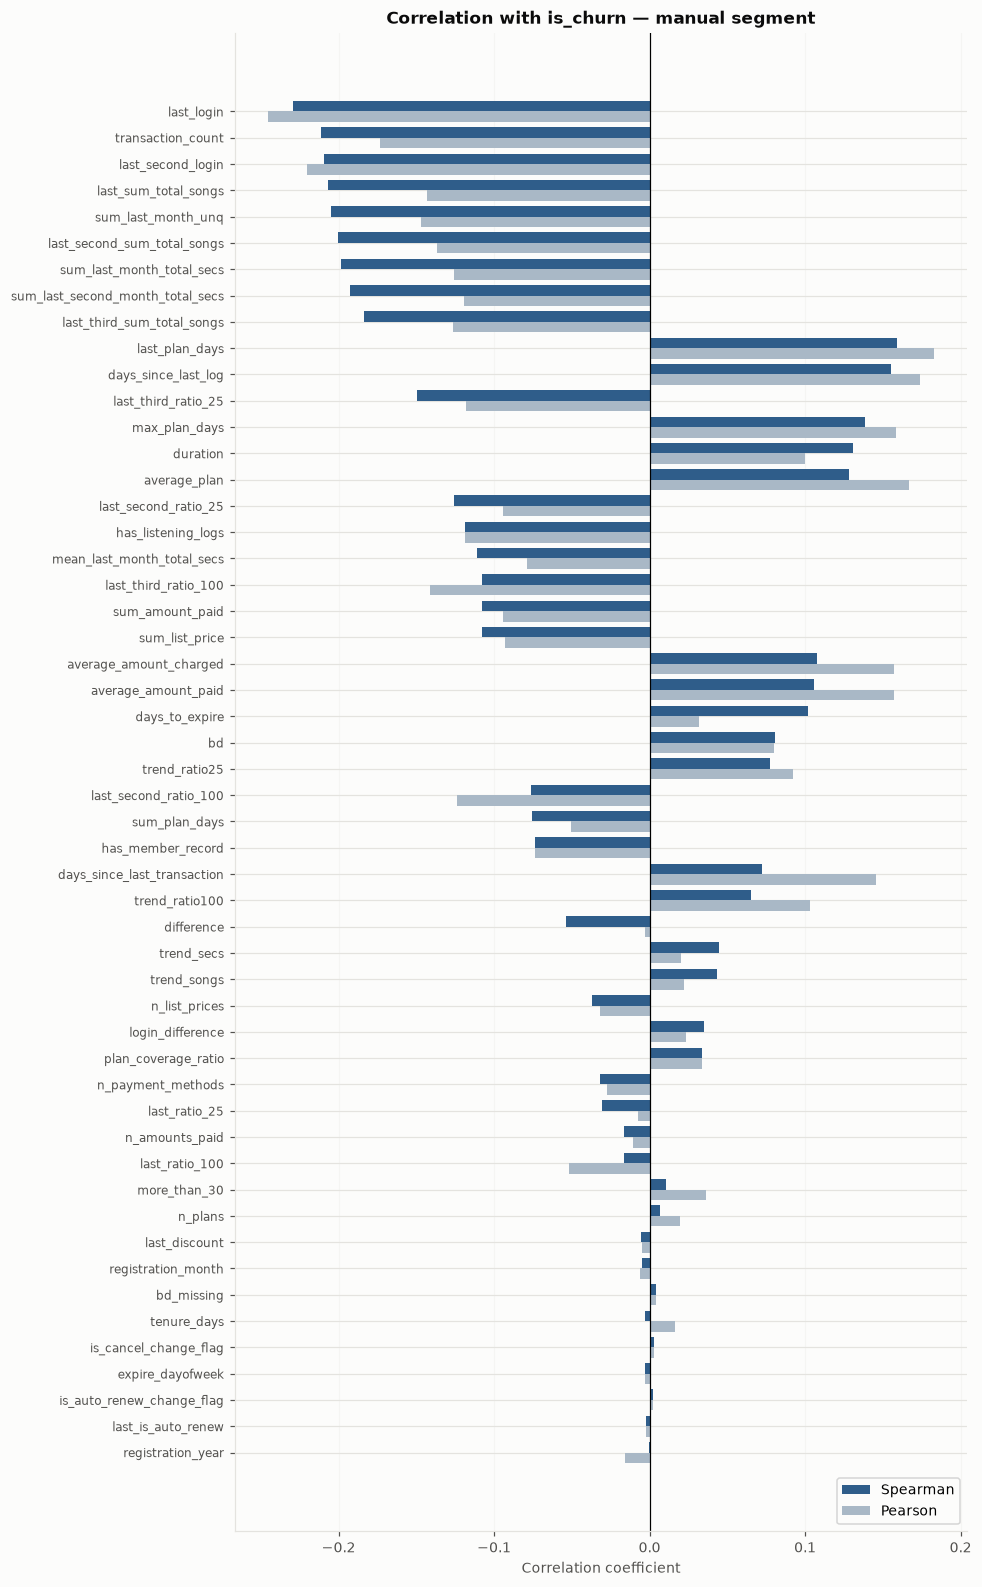

In [7]:
from sklearn.metrics import roc_auc_score


def univariate_auc(values):
    mask = values.notna()
    return roc_auc_score(y[mask], values[mask])


numeric_corr = pd.DataFrame({
    'domain':   catalogue.loc[NUMERIC, 'domain'],
    'type':     catalogue.loc[NUMERIC, 'type'],
    'pearson':  df[NUMERIC].corrwith(y),
    'spearman': df[NUMERIC].corrwith(y, method='spearman'),
    'roc_auc':  [univariate_auc(df[f]) for f in NUMERIC],
})
numeric_corr = numeric_corr.reindex(numeric_corr['spearman'].abs().sort_values(ascending=False).index)
display(numeric_corr.round(4))

order = numeric_corr.index[::-1]
positions = np.arange(len(order))
bar_height = 0.4
fig, ax = plt.subplots(figsize=(9, 0.25 * len(order) + 1.5))
ax.barh(positions + bar_height / 2, numeric_corr.loc[order, 'spearman'], bar_height,
        label='Spearman', color='#2f5d8a')
ax.barh(positions - bar_height / 2, numeric_corr.loc[order, 'pearson'], bar_height,
        label='Pearson', color='#a9b8c6')
ax.set_yticks(positions, labels=order, fontsize=8)
ax.axvline(0, color='black', linewidth=0.8)
ax.set(title='Correlation with is_churn — manual segment', xlabel='Correlation coefficient')
ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(GRAPHICS_DIR / 'churn_numeric_correlations.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

## 6. Categorical features and churn

,domain,n_levels,cramers_v
feature,,,
last_payment_method_id,transactions,21,0.1604
city,member,21,0.0757
registered_via,member,5,0.0631


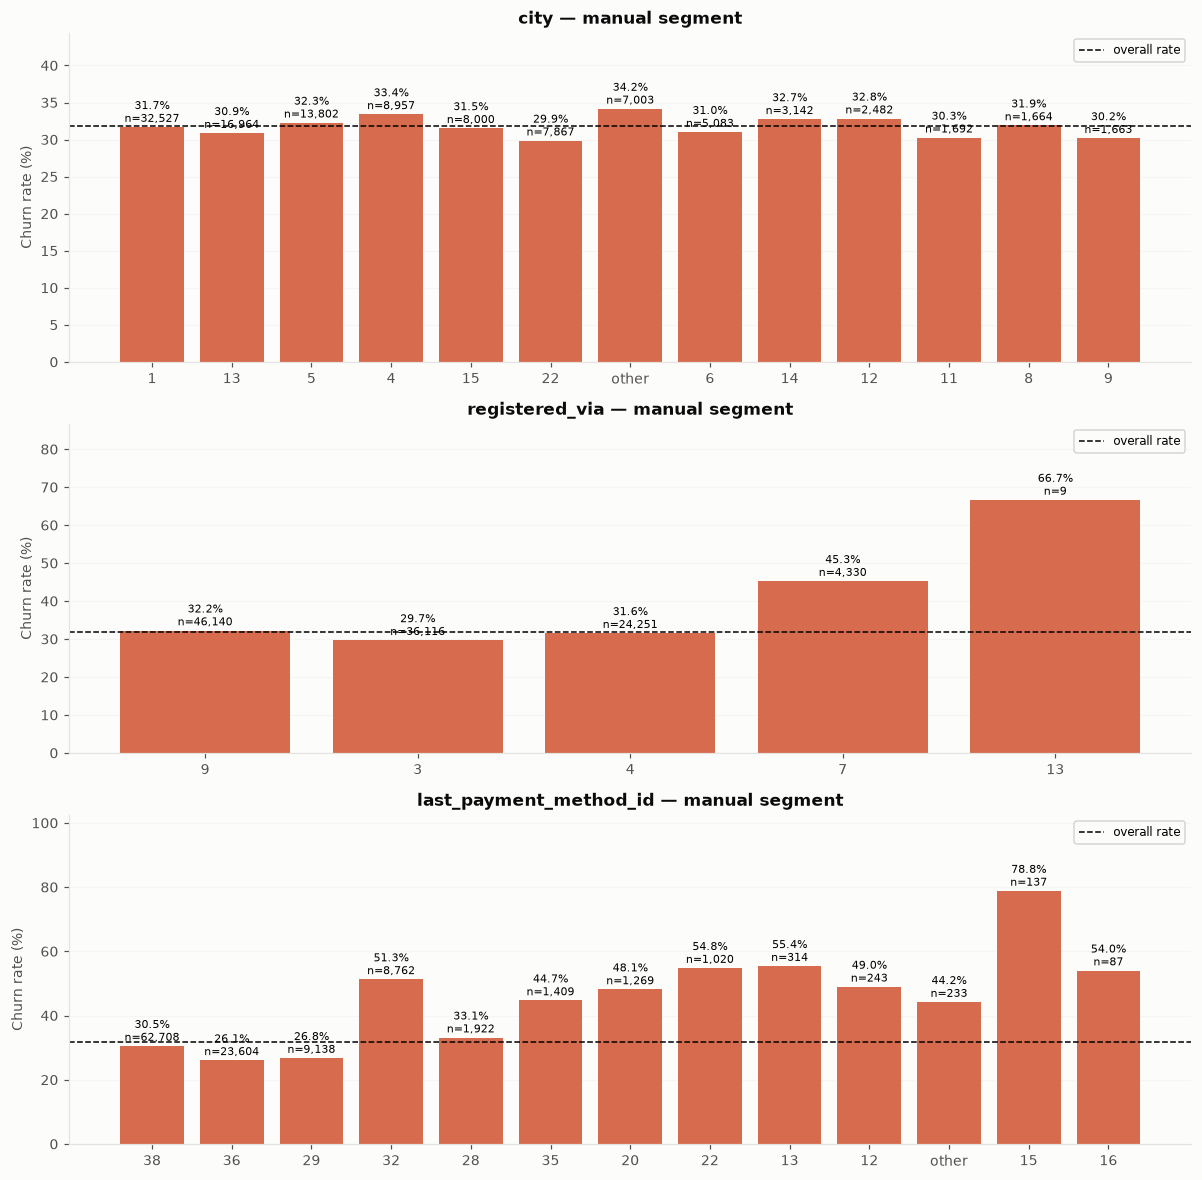

In [8]:
from scipy.stats import chi2_contingency

MAX_LEVELS = 12


def as_levels(series):
    labels = series.astype('Int64').astype('string').fillna('missing')
    top = labels.value_counts().index[:MAX_LEVELS]
    return labels.where(labels.isin(top), 'other')


def cramers_v(table):
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    rows, cols = table.shape
    phi2    = max(0.0, chi2 / n - (rows - 1) * (cols - 1) / (n - 1))
    rows_c  = rows - (rows - 1) ** 2 / (n - 1)
    cols_c  = cols - (cols - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(rows_c - 1, cols_c - 1))


cat_features = [f for f in TYPES['categorical'] if f in df.columns]
categorical_assoc = pd.DataFrame({
    'domain':   catalogue.loc[cat_features, 'domain'],
    'n_levels': catalogue.loc[cat_features, 'n_unique'],
    'cramers_v': [
        cramers_v(pd.crosstab(df[f].astype('Int64').astype('string').fillna('missing'), y))
        for f in cat_features
    ],
}).sort_values('cramers_v', ascending=False)
display(categorical_assoc.round(4))

if cat_features:
    fig, axes = plt.subplots(len(cat_features), 1,
                             figsize=(11, 3.6 * len(cat_features)), squeeze=False)
    for axis, feature in zip(axes.flat, cat_features):
        levels = as_levels(df[feature])
        stats  = y.groupby(levels).agg(['mean', 'size']).sort_values('size', ascending=False)
        bars   = axis.bar(stats.index, stats['mean'] * 100, color=churn_colors[1])
        axis.axhline(BASE_RATE * 100, color='black', linestyle='--', linewidth=1, label='overall rate')
        axis.bar_label(bars,
                       labels=[f'{r:.1%}\nn={n:,}' for r, n in zip(stats['mean'], stats['size'])],
                       padding=1, fontsize=7)
        axis.set_title(f'{feature} — manual segment')
        axis.set_ylabel('Churn rate (%)')
        axis.set_ylim(0, stats['mean'].max() * 100 * 1.3)
        axis.grid(axis='y', alpha=0.25)
        axis.set_axisbelow(True)
        axis.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(GRAPHICS_DIR / 'churn_categorical_relationships.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

## 7. Binary and discrete features and churn

Saved: churn_binary_relationships_01.png


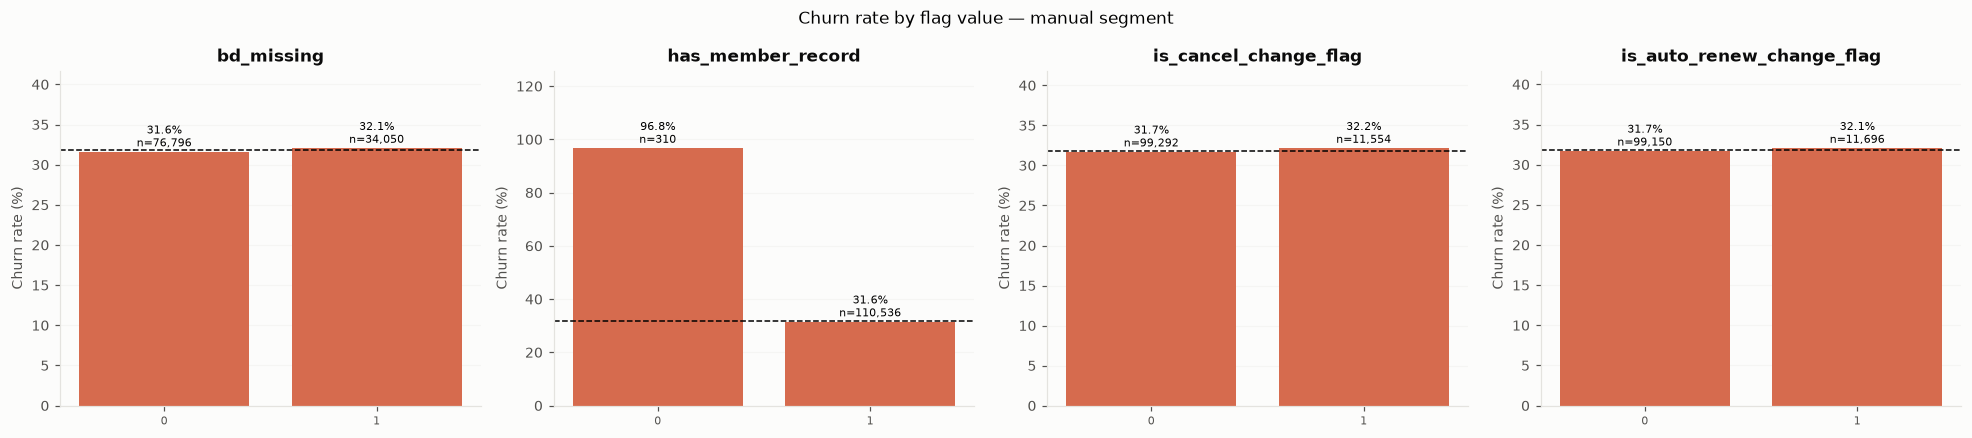

Saved: churn_binary_relationships_02.png


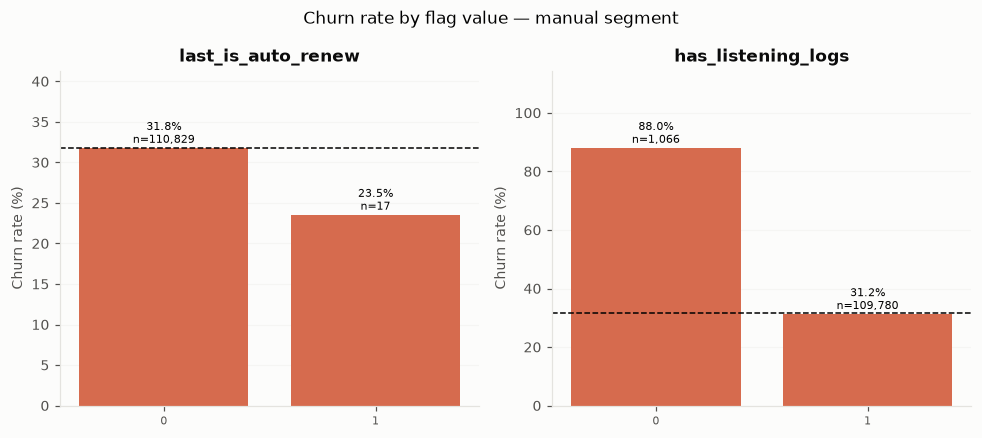

Saved: churn_discrete_relationships_01.png


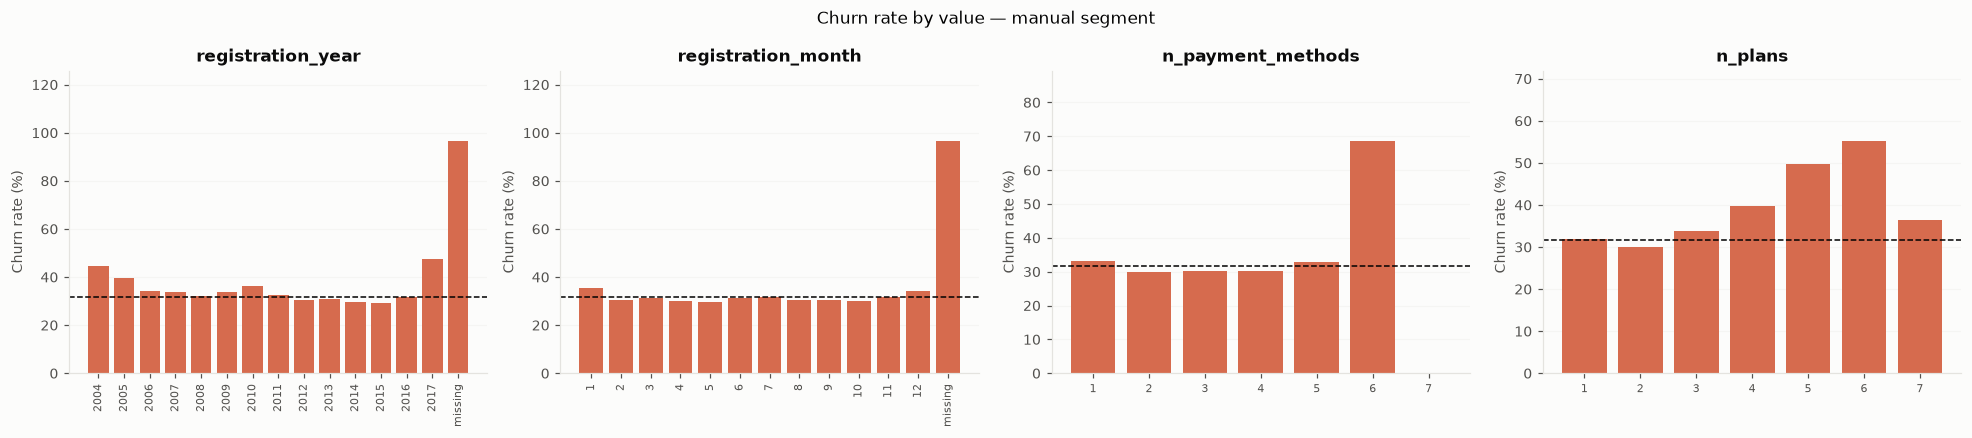

Saved: churn_discrete_relationships_02.png


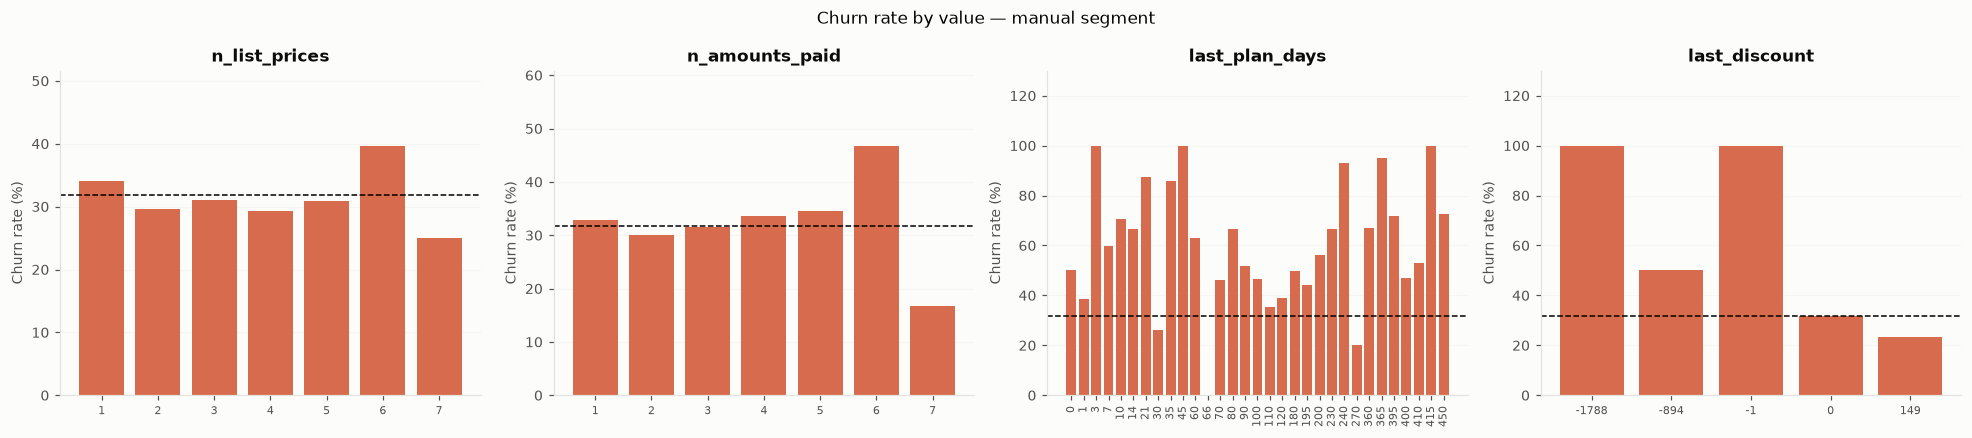

Saved: churn_discrete_relationships_03.png


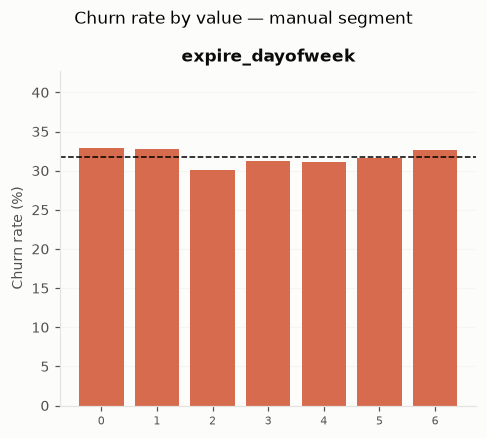

In [9]:
def plot_rate_by_value(features, filename, title):
    for index in range(0, len(features), 4):
        group = features[index:index + 4]
        fig, axes = plt.subplots(1, len(group), figsize=(4.5 * len(group), 4), squeeze=False)
        for axis, feature in zip(axes.flat, group):
            values = df[feature].astype('Float64').round().astype('Int64').astype('string').fillna('missing')
            stats  = y.groupby(values).agg(['mean', 'size'])
            numeric_keys = pd.to_numeric(stats.index.to_series(), errors='coerce').astype(float).fillna(np.inf)
            stats  = stats.iloc[np.argsort(numeric_keys.to_numpy(), kind='stable')]
            bars   = axis.bar(stats.index, stats['mean'] * 100, color=churn_colors[1])
            axis.axhline(BASE_RATE * 100, color='black', linestyle='--', linewidth=1)
            if len(stats) <= 4:
                axis.bar_label(bars,
                               labels=[f'{r:.1%}\nn={n:,}' for r, n in zip(stats['mean'], stats['size'])],
                               padding=1, fontsize=7)
            axis.set_ylim(0, stats['mean'].max() * 100 * 1.3)
            axis.tick_params(axis='x', labelsize=7, rotation=90 if len(stats) > 12 else 0)
            axis.set_title(feature)
            axis.set_ylabel('Churn rate (%)')
            axis.grid(axis='y', alpha=0.25)
            axis.set_axisbelow(True)
        fig.suptitle(f'{title} — manual segment')
        fig.tight_layout()
        output_path = GRAPHICS_DIR / f'{filename}_{index // 4 + 1:02d}.png'
        fig.savefig(output_path, dpi=300, bbox_inches='tight')
        print(f'Saved: {output_path.name}')
        plt.show()
        plt.close(fig)


plot_rate_by_value(TYPES['binary'],   'churn_binary_relationships',   'Churn rate by flag value')
plot_rate_by_value(TYPES['discrete'], 'churn_discrete_relationships', 'Churn rate by value')

## 8. Continuous features and churn

Saved: churn_continuous_relationships_01.png


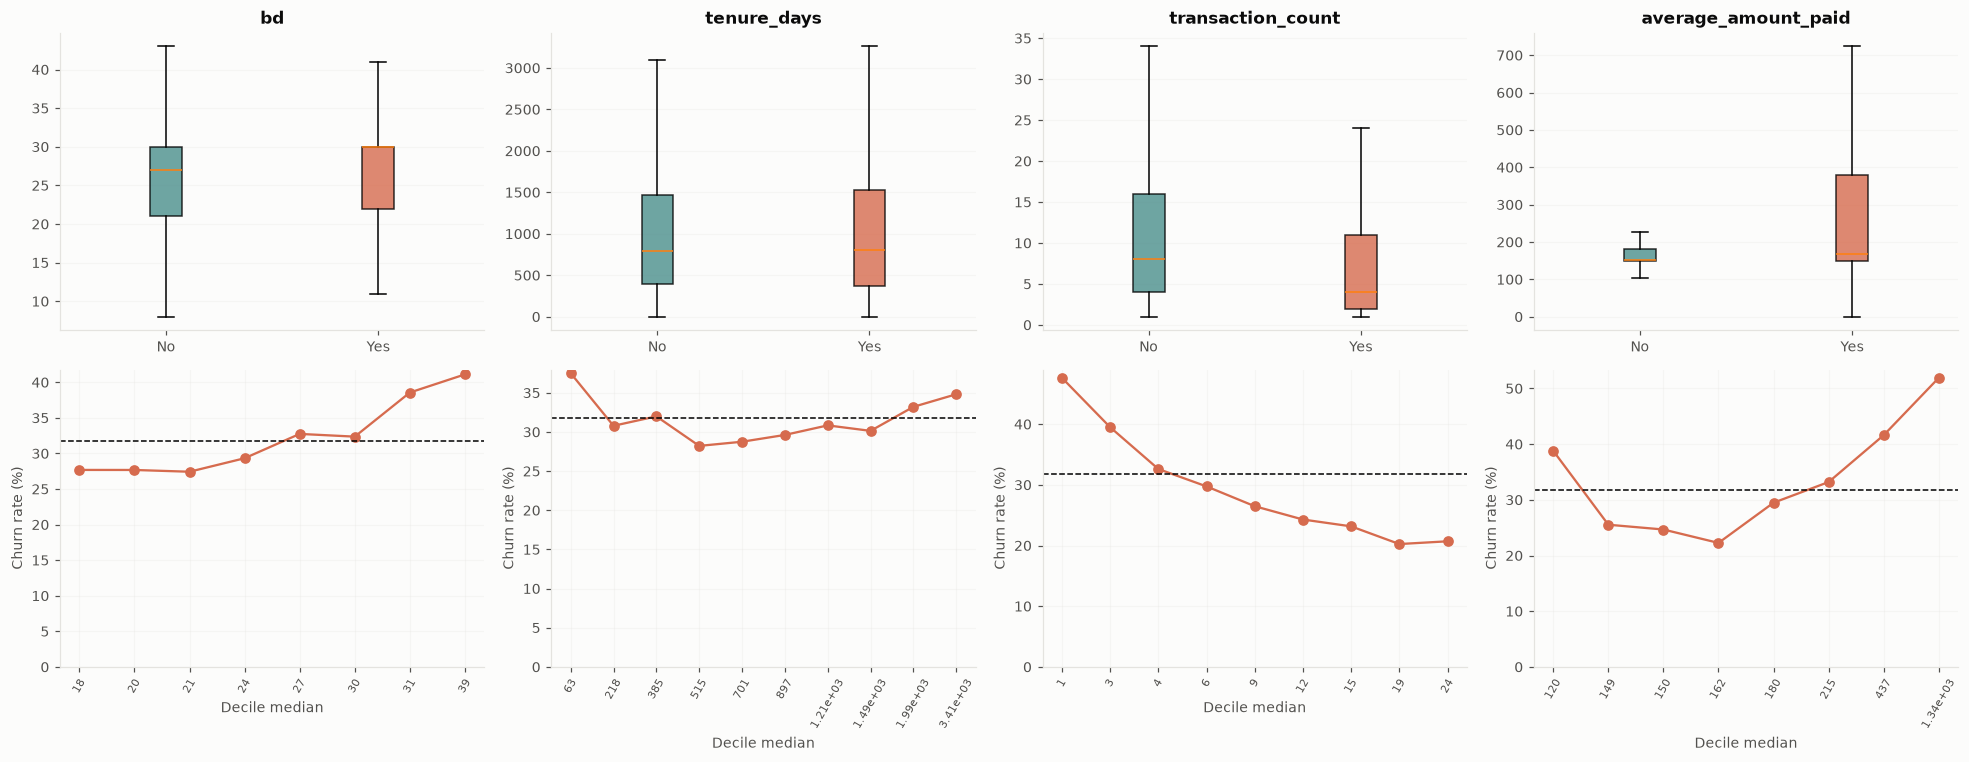

Saved: churn_continuous_relationships_02.png


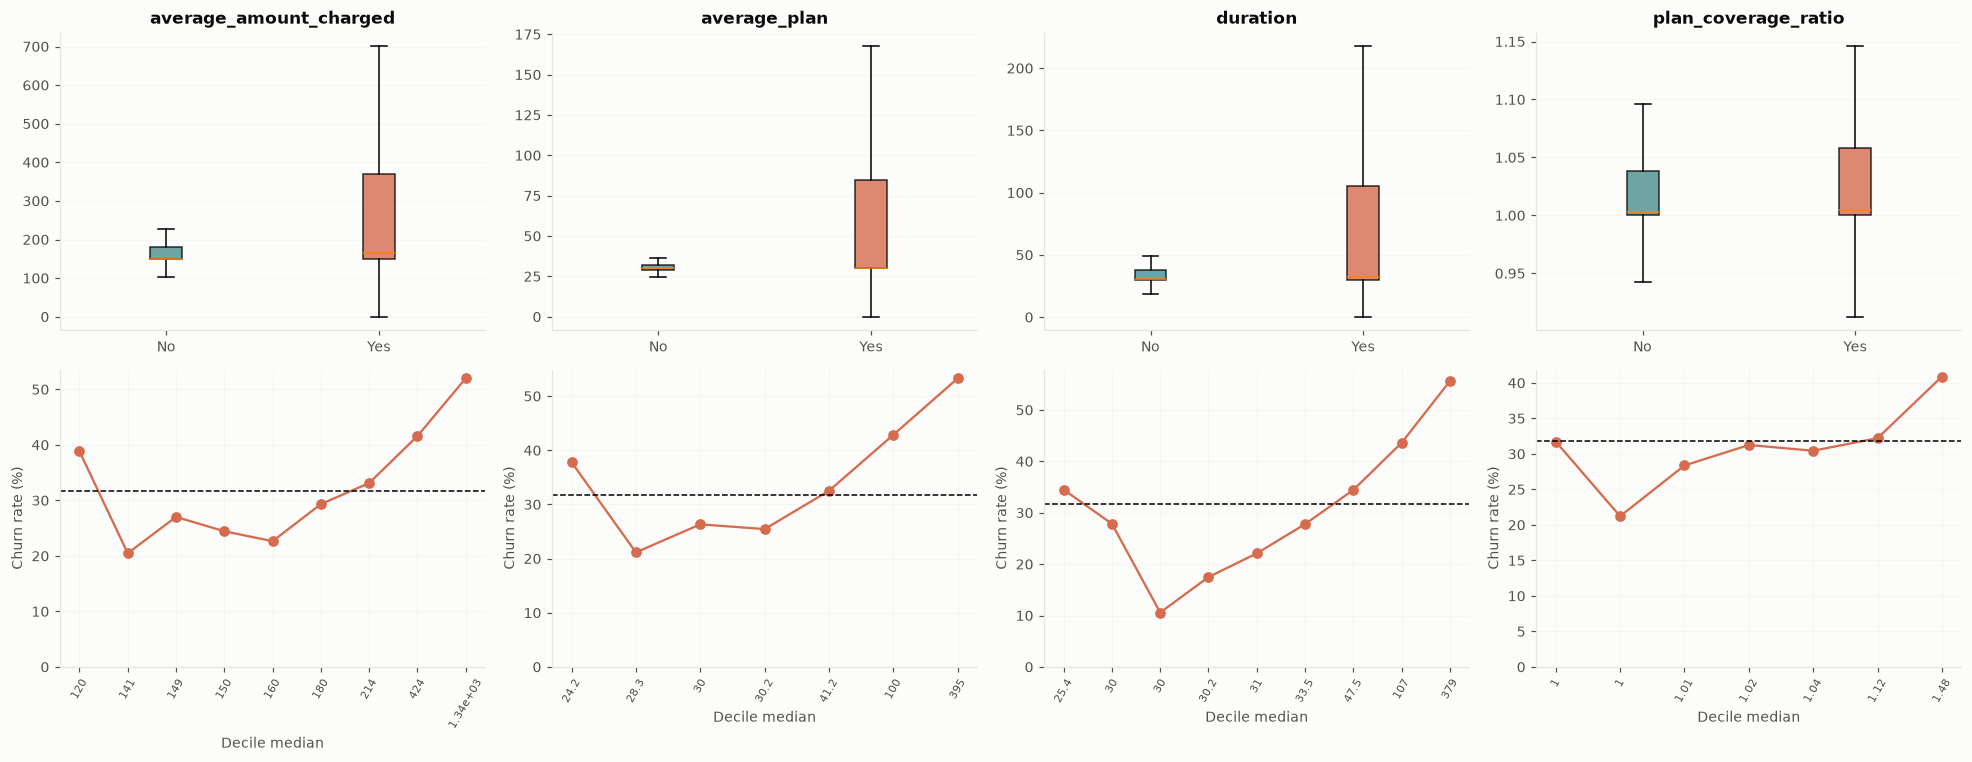

Saved: churn_continuous_relationships_03.png


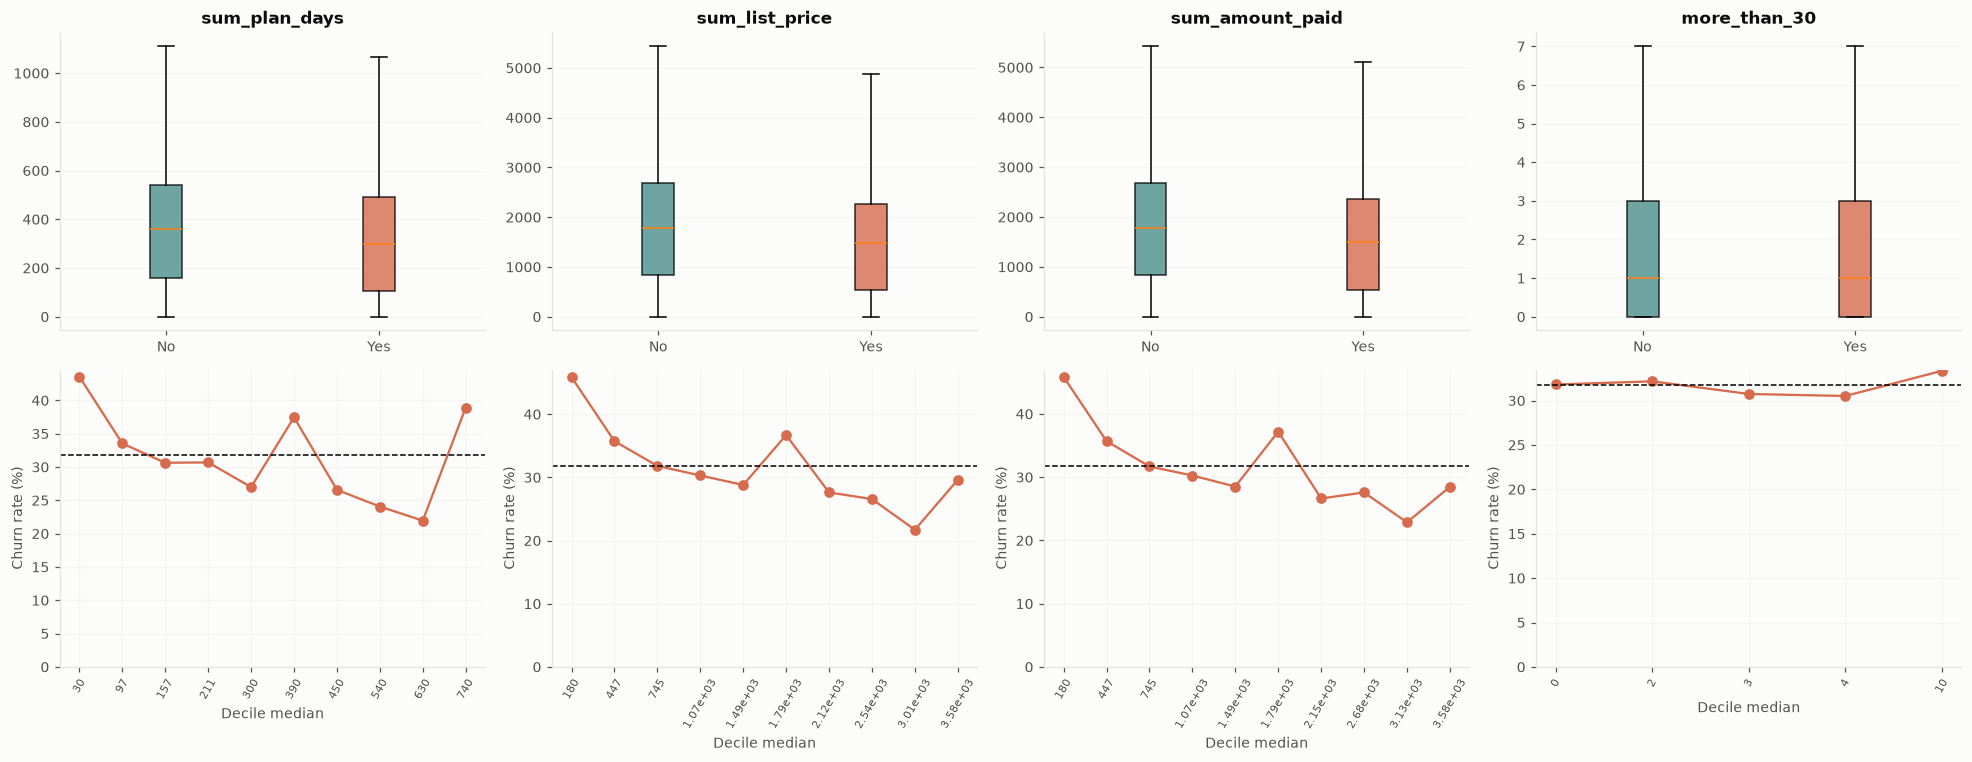

Saved: churn_continuous_relationships_04.png


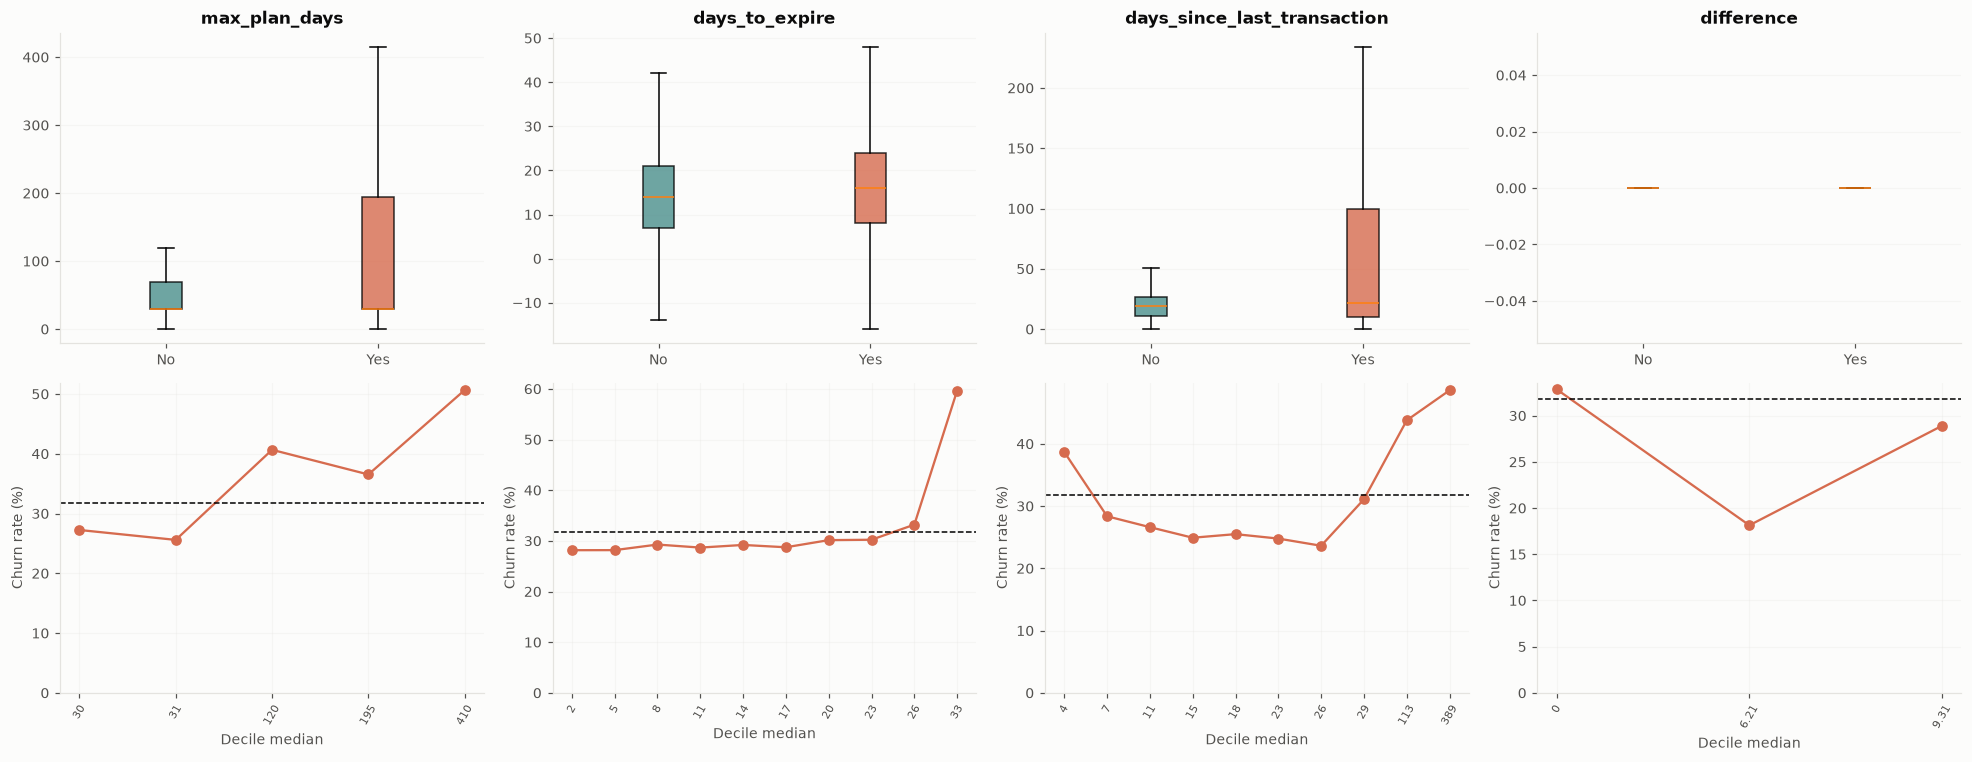

Saved: churn_continuous_relationships_05.png


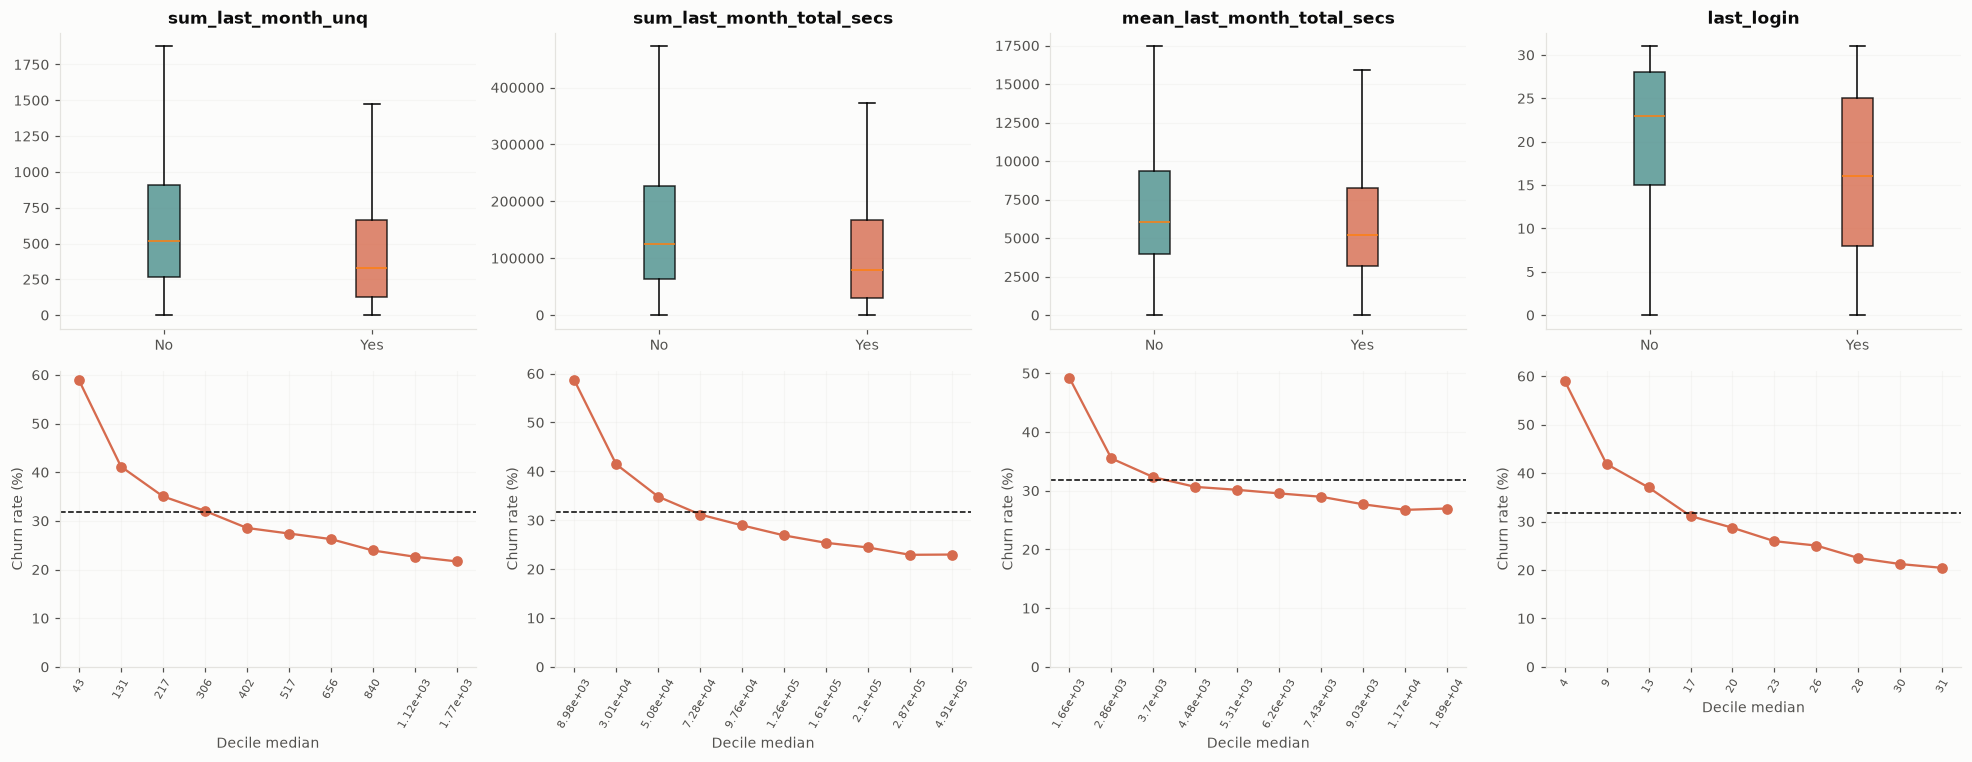

Saved: churn_continuous_relationships_06.png


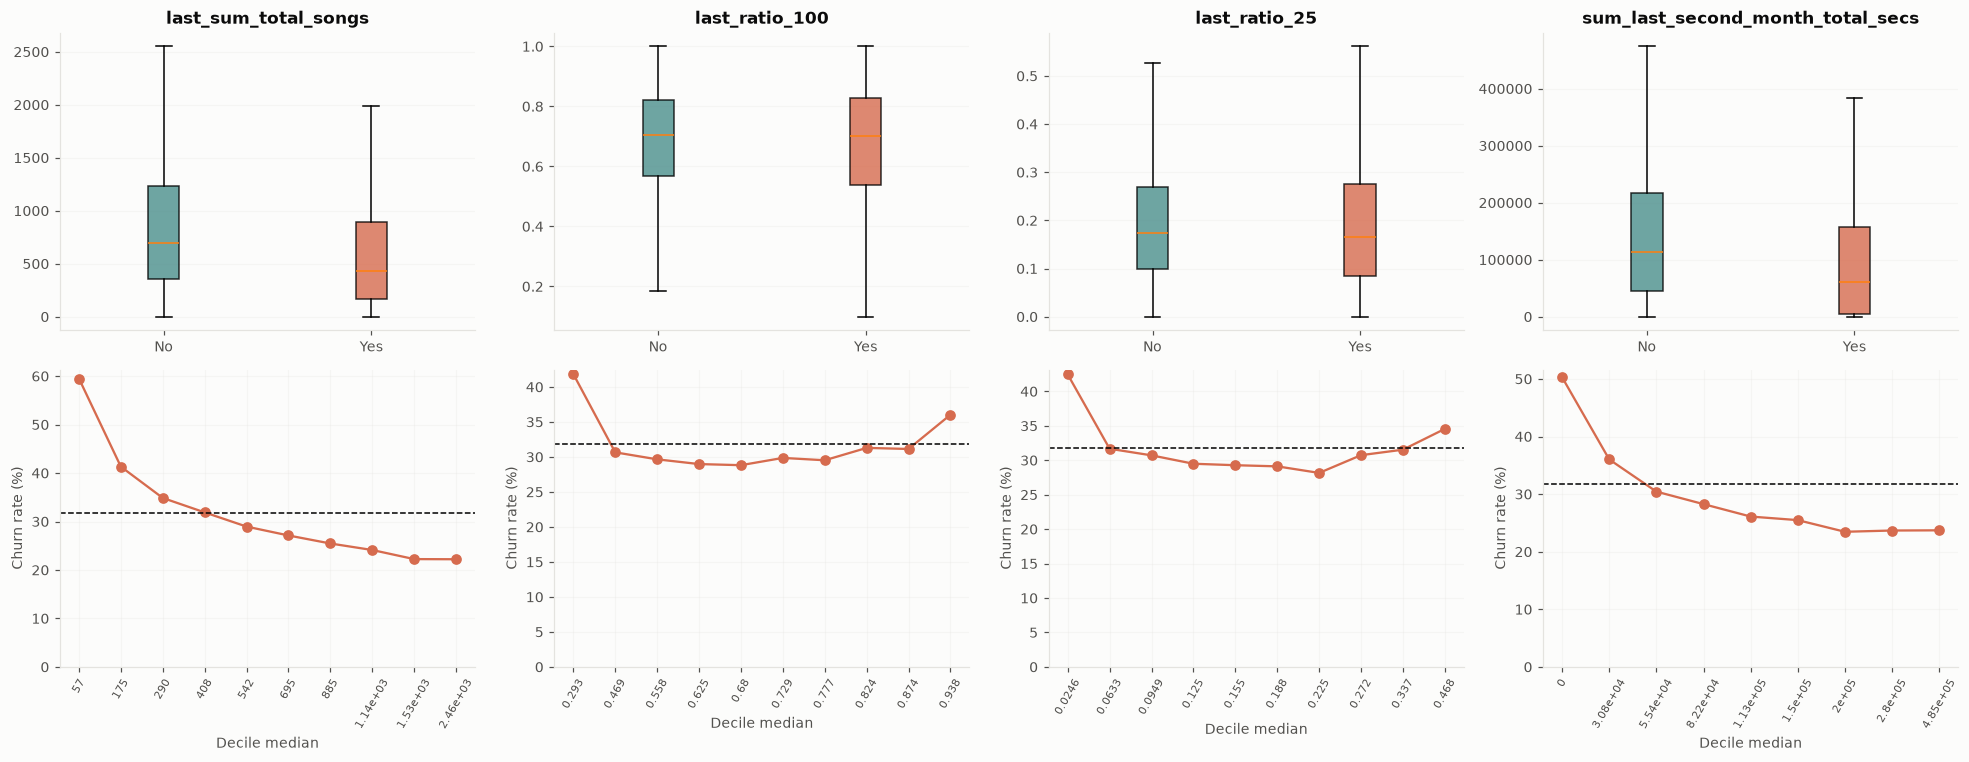

Saved: churn_continuous_relationships_07.png


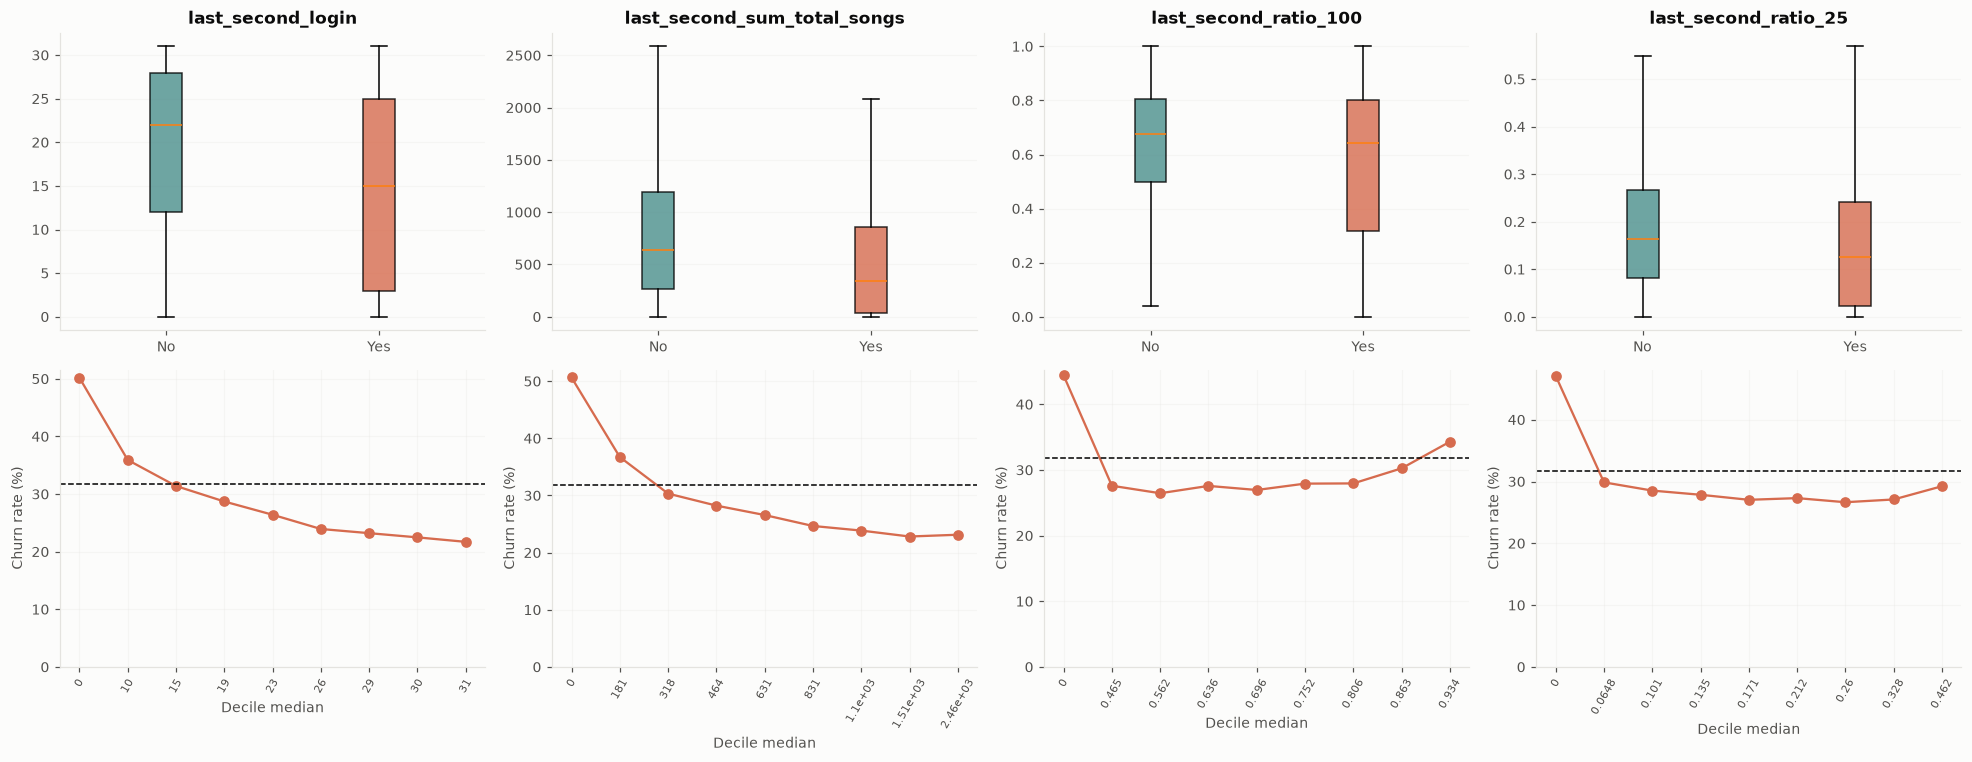

Saved: churn_continuous_relationships_08.png


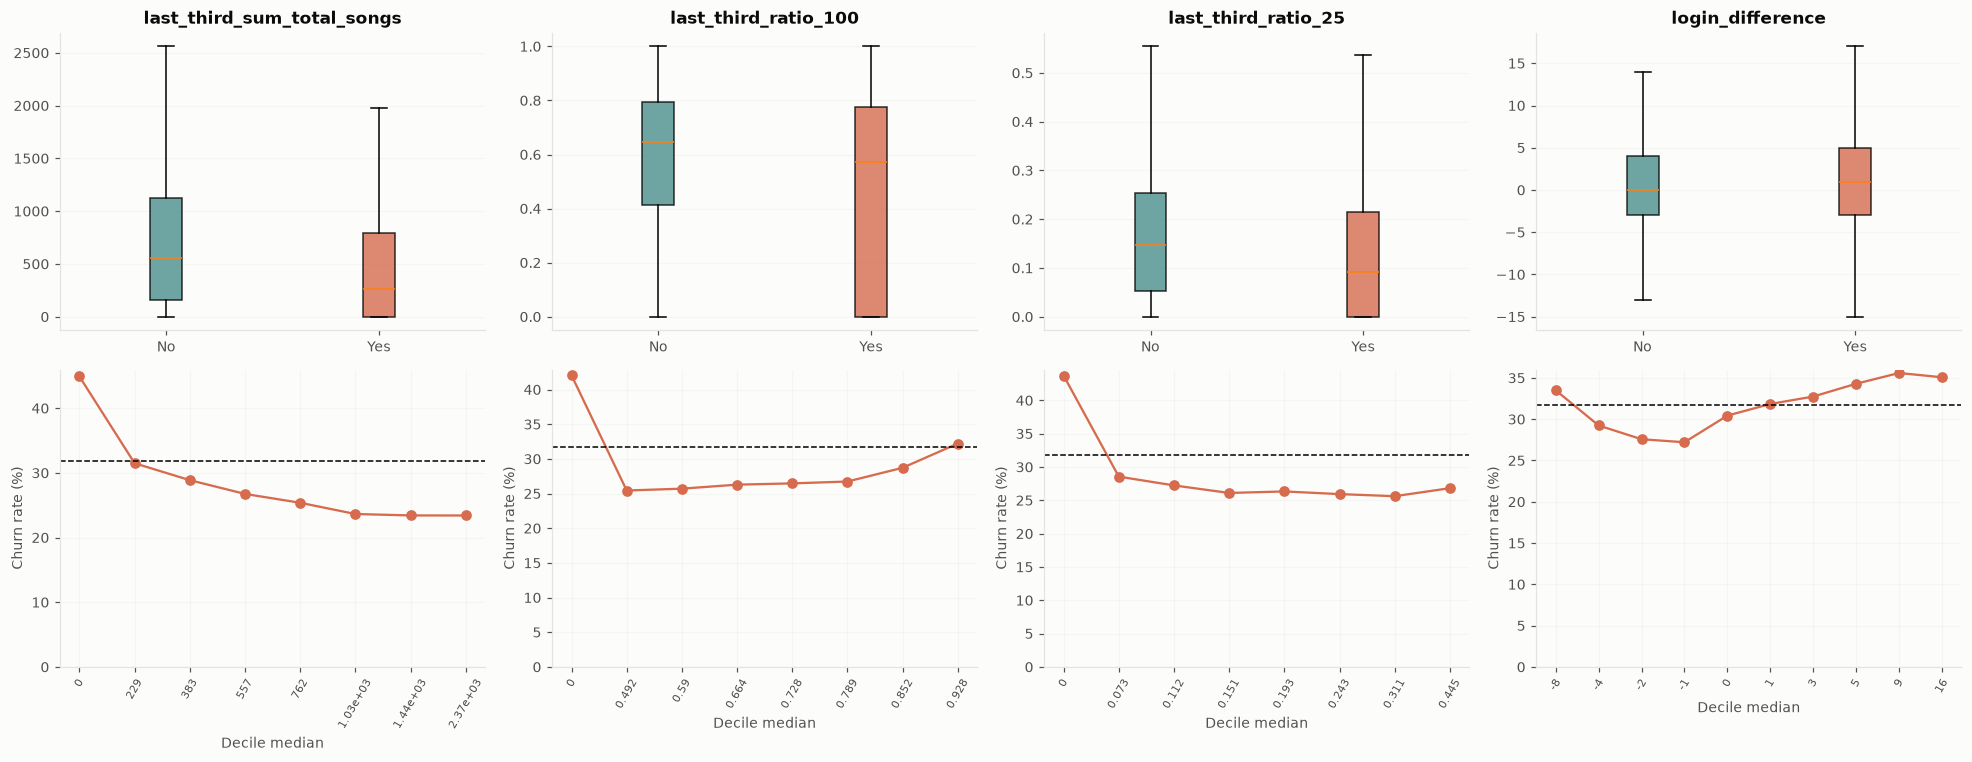

Saved: churn_continuous_relationships_09.png


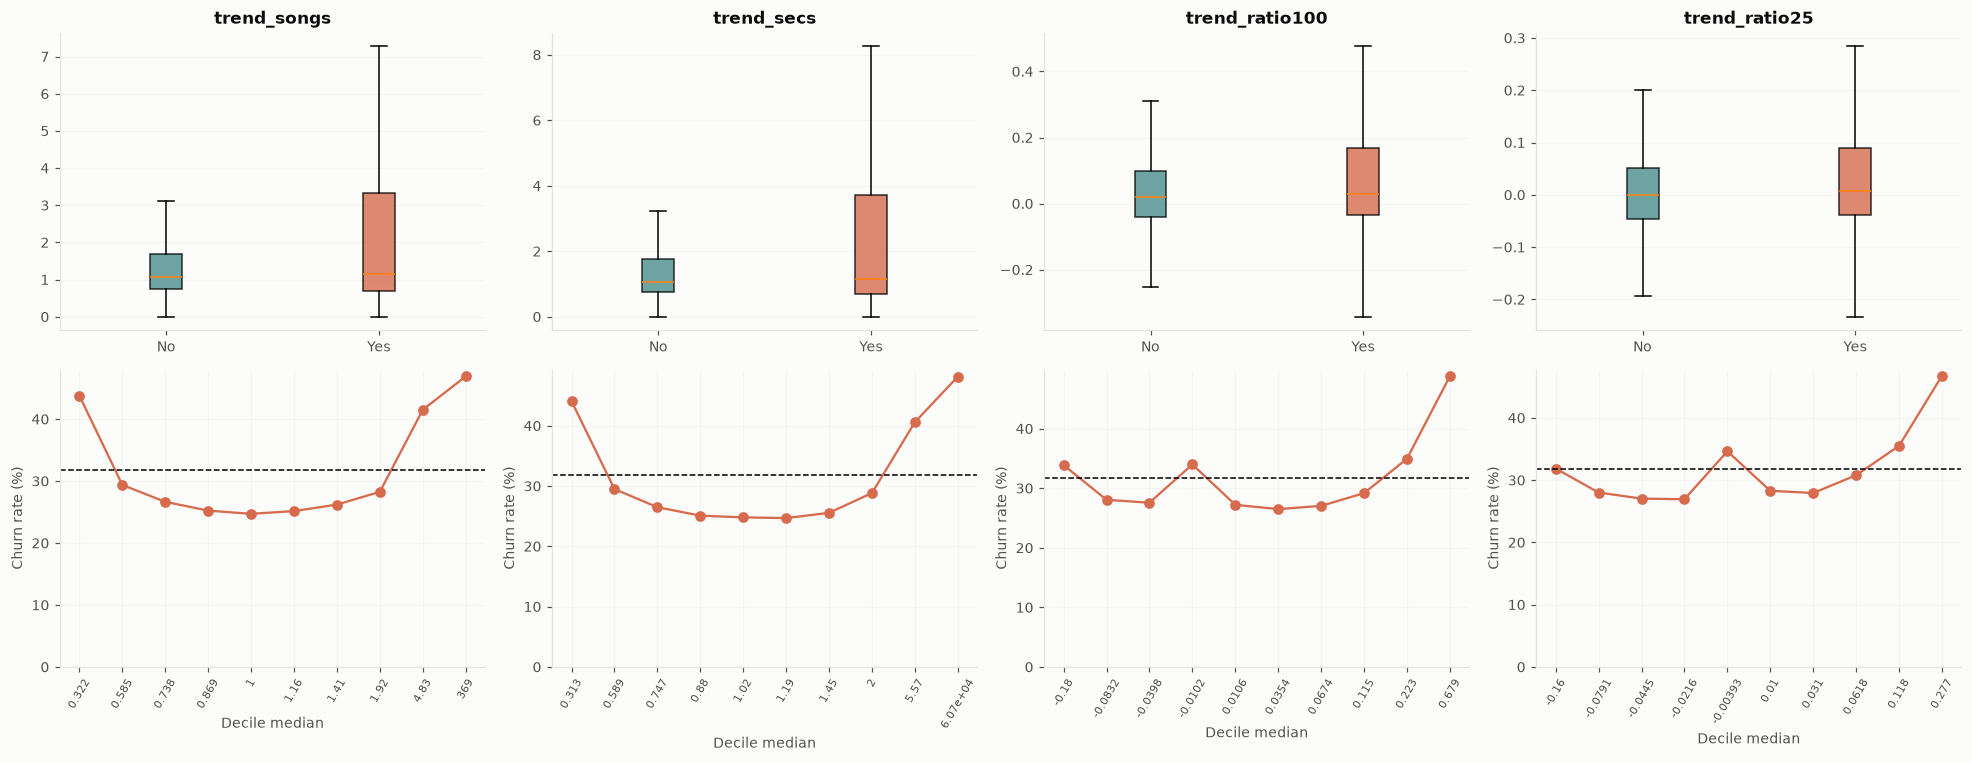

Saved: churn_continuous_relationships_10.png


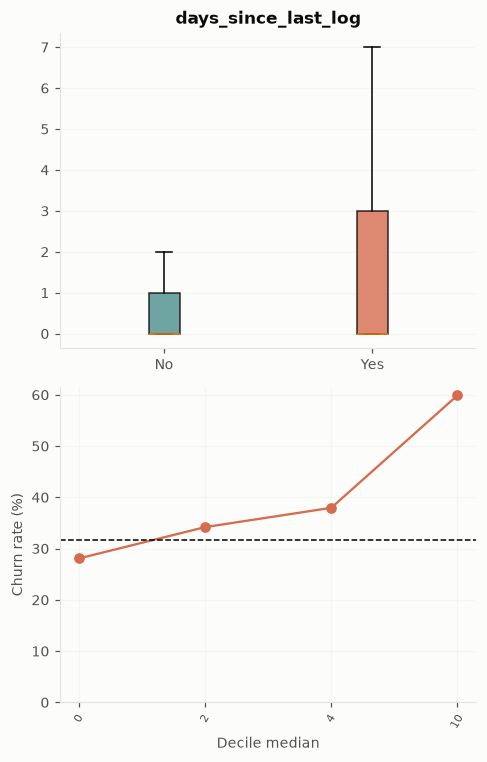

In [10]:
continuous = TYPES['continuous']
for index in range(0, len(continuous), 4):
    group = continuous[index:index + 4]
    fig, axes = plt.subplots(2, len(group), figsize=(4.5 * len(group), 7), squeeze=False)
    for column, feature in enumerate(group):
        values   = df[feature]
        box_axis = axes[0, column]
        rate_axis = axes[1, column]

        class_values = [values[y.eq(label)].dropna().to_numpy() for label in (0, 1)]
        boxplots = box_axis.boxplot(class_values, patch_artist=True, showfliers=False)
        for box, color in zip(boxplots['boxes'], churn_colors):
            box.set_facecolor(color)
            box.set_alpha(0.8)
        box_axis.set_xticks([1, 2], labels=churn_labels)
        box_axis.set_title(feature)
        box_axis.grid(axis='y', alpha=0.25)

        mask    = values.notna()
        deciles = pd.qcut(values[mask], 10, duplicates='drop')
        stats   = pd.DataFrame({'x': values[mask], 'y': y[mask], 'bin': deciles}).groupby(
            'bin', observed=True).agg(median=('x', 'median'), rate=('y', 'mean'))
        rate_axis.plot(np.arange(len(stats)), stats['rate'] * 100, marker='o', color=churn_colors[1])
        rate_axis.axhline(BASE_RATE * 100, color='black', linestyle='--', linewidth=1)
        rate_axis.set_xticks(np.arange(len(stats)),
                             labels=[f'{m:.3g}' for m in stats['median']],
                             rotation=60, fontsize=7)
        rate_axis.set_xlabel('Decile median')
        rate_axis.set_ylabel('Churn rate (%)')
        rate_axis.set_ylim(bottom=0)
        rate_axis.grid(alpha=0.25)
    fig.tight_layout()
    output_path = GRAPHICS_DIR / f'churn_continuous_relationships_{index // 4 + 1:02d}.png'
    fig.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f'Saved: {output_path.name}')
    plt.show()
    plt.close(fig)

## 9. Feature-feature correlations

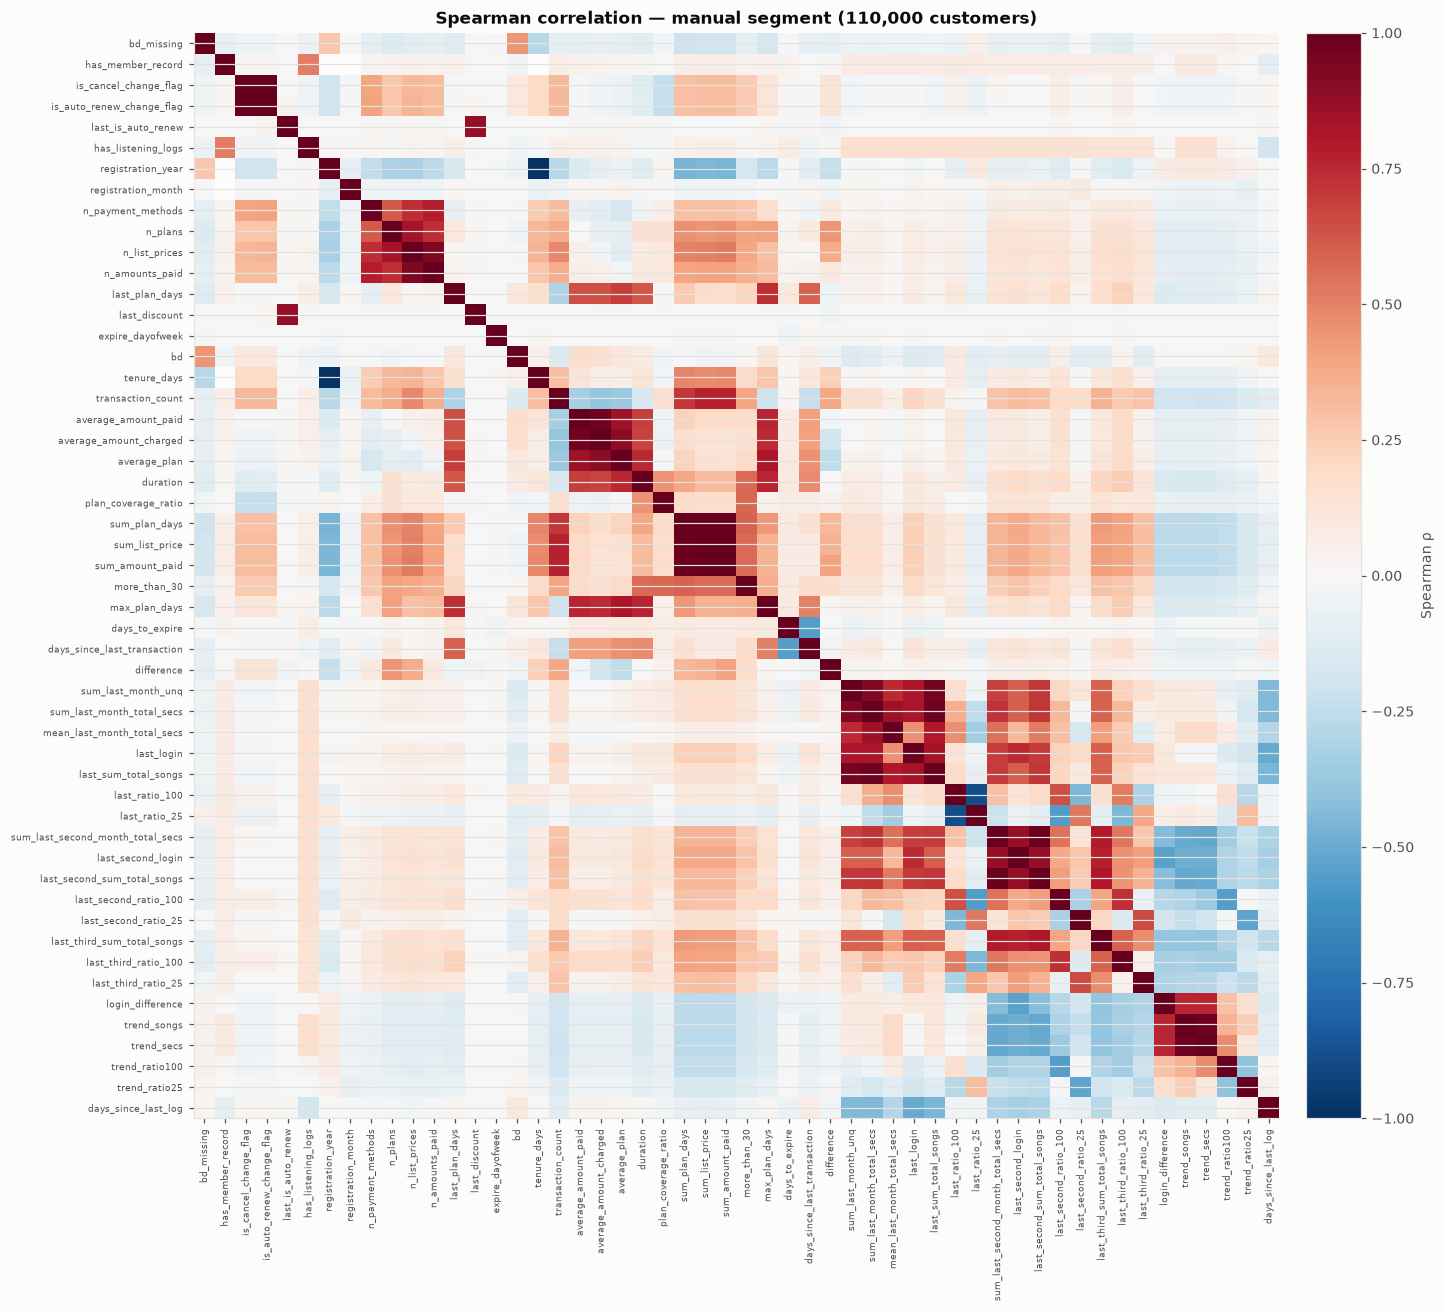

Pairs with |rho| >= 0.9: 12


,feature_a,feature_b,spearman
0,sum_list_price,sum_amount_paid,0.996
1,is_cancel_change_flag,is_auto_renew_change_flag,0.993
2,registration_year,tenure_days,-0.985
3,sum_plan_days,sum_list_price,0.982
4,sum_last_second_month_total_secs,last_second_sum_total_songs,0.981
5,sum_plan_days,sum_amount_paid,0.978
6,trend_songs,trend_secs,0.975
7,sum_last_month_total_secs,last_sum_total_songs,0.973
8,average_amount_paid,average_amount_charged,0.968
9,sum_last_month_unq,last_sum_total_songs,0.959


In [11]:
SAMPLE_SIZE = 110_000  # manual segment is ~110K, use all
SEED = 42

sample = df.groupby('is_churn', group_keys=False).sample(
    frac=min(1.0, SAMPLE_SIZE / len(df)), random_state=SEED
)
feature_corr = sample[NUMERIC].corr(method='spearman')

fig, ax = plt.subplots(figsize=(14, 12))
image = ax.imshow(feature_corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(NUMERIC)), labels=NUMERIC, rotation=90, fontsize=6)
ax.set_yticks(np.arange(len(NUMERIC)), labels=NUMERIC, fontsize=6)
ax.set_title(f'Spearman correlation — manual segment ({len(sample):,} customers)')
fig.colorbar(image, ax=ax, fraction=0.04, pad=0.02, label='Spearman ρ')
fig.tight_layout()
fig.savefig(GRAPHICS_DIR / 'feature_correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

upper = feature_corr.where(np.triu(np.ones(feature_corr.shape, dtype=bool), k=1))
redundant = upper.stack().rename('spearman').reset_index()
redundant.columns = ['feature_a', 'feature_b', 'spearman']
redundant = redundant[redundant['spearman'].abs().ge(0.9)]
redundant = redundant.reindex(redundant['spearman'].abs().sort_values(ascending=False).index)
print(f'Pairs with |rho| >= 0.9: {len(redundant)}')
display(redundant.round(3).reset_index(drop=True))

## 10. Unified ranking — mutual information

,rank,domain,type,missing_pct,pearson,spearman,roc_auc,cramers_v,mutual_info
feature,,,,,,,,,
duration,1,transactions,continuous,0.0000,0.1001,0.1310,0.5806,NaN,0.0396
sum_amount_paid,2,transactions,continuous,0.0000,-0.0940,-0.1078,0.4332,NaN,0.0382
average_plan,3,transactions,continuous,0.0000,0.1665,0.1280,0.5758,NaN,0.0376
average_amount_charged,4,transactions,continuous,0.0000,0.1573,0.1077,0.5662,NaN,0.0369
sum_plan_days,5,transactions,continuous,0.0000,-0.0506,-0.0754,0.4533,NaN,0.0357
average_amount_paid,6,transactions,continuous,0.0000,0.1569,0.1054,0.5646,NaN,0.0352
last_login,7,logs,continuous,0.0000,-0.2454,-0.2295,0.3578,NaN,0.0349
sum_list_price,8,transactions,continuous,0.0000,-0.0931,-0.1077,0.4332,NaN,0.0347
days_to_expire,9,transactions,continuous,0.0000,0.0320,0.1021,0.5633,NaN,0.0339


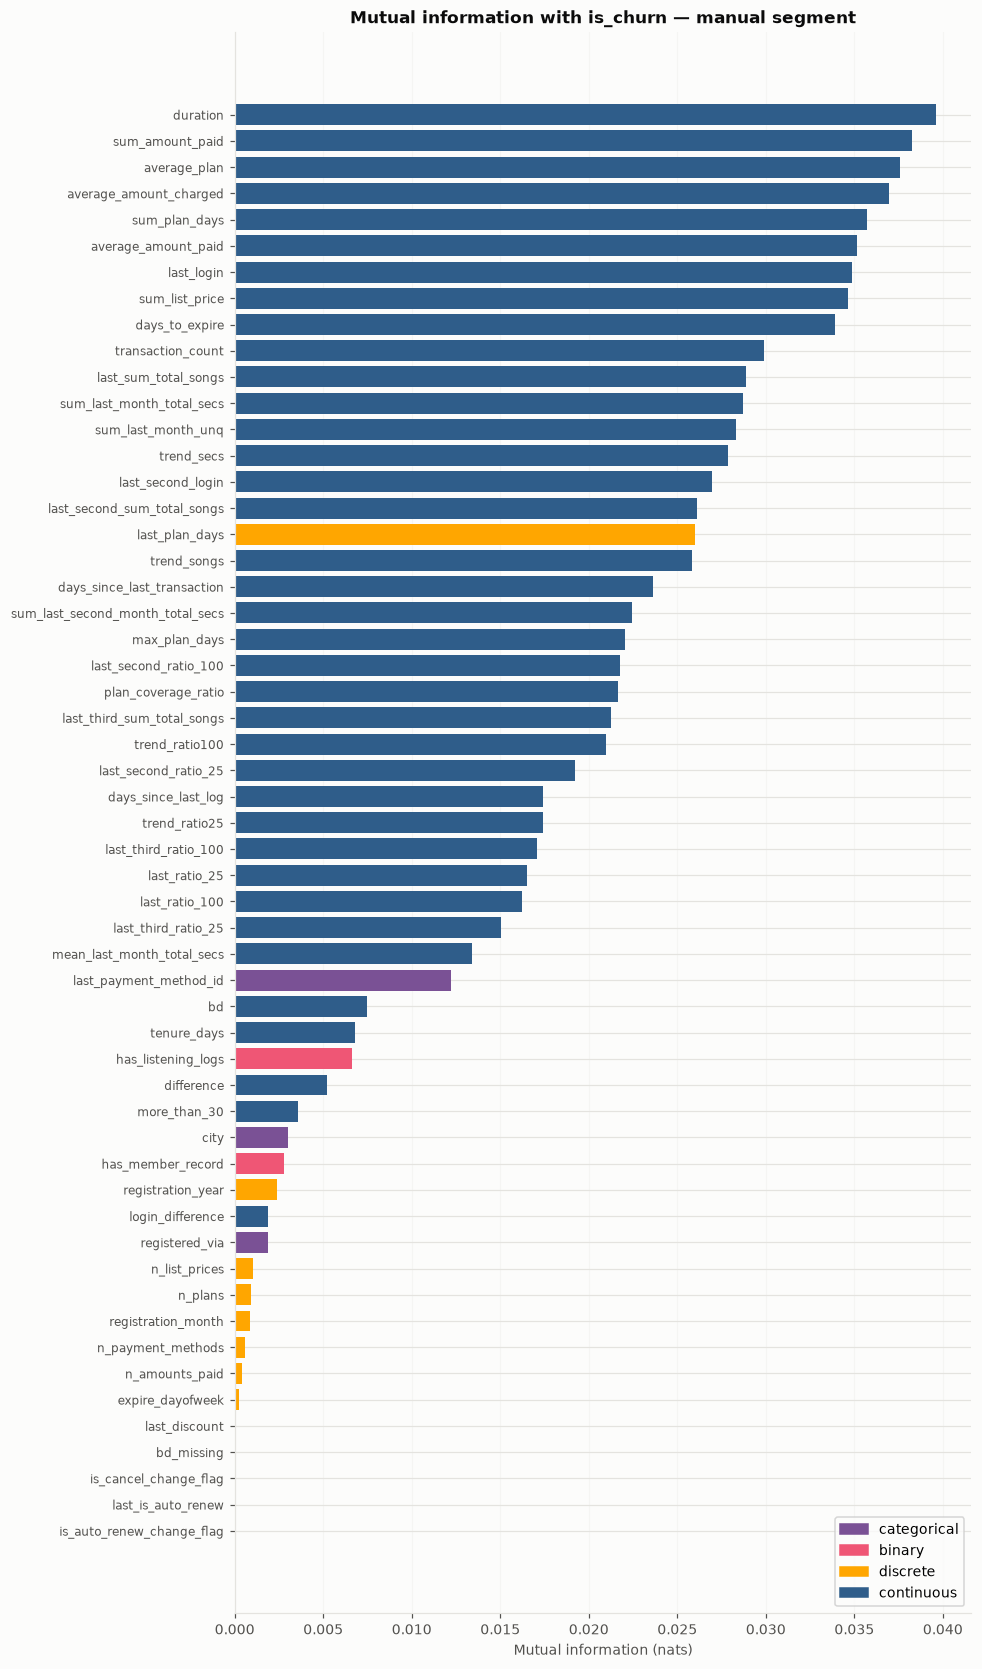


Top 5 features by domain (manual segment):
  transactions: duration, sum_amount_paid, average_plan, average_amount_charged, sum_plan_days
  logs: last_login, last_sum_total_songs, sum_last_month_total_secs, sum_last_month_unq, trend_secs
  member: bd, tenure_days, city, has_member_record, registration_year


In [12]:
from sklearn.feature_selection import mutual_info_classif

ranked   = cat_features + NUMERIC
X_sample = sample[ranked].copy()
for feature in cat_features:
    X_sample[feature] = X_sample[feature].fillna(-1)
X_sample[NUMERIC] = X_sample[NUMERIC].fillna(X_sample[NUMERIC].median())
discrete_mask = [feature not in TYPES['continuous'] for feature in ranked]

mutual_info = pd.Series(
    mutual_info_classif(X_sample.to_numpy(dtype=float), sample['is_churn'].to_numpy(),
                        discrete_features=discrete_mask, random_state=SEED),
    index=ranked, name='mutual_info',
)

feature_ranking = (
    catalogue.loc[ranked, ['domain', 'type', 'missing_pct']]
    .join(numeric_corr[['pearson', 'spearman', 'roc_auc']])
    .join(categorical_assoc[['cramers_v']])
    .join(mutual_info)
    .sort_values('mutual_info', ascending=False)
)
feature_ranking.insert(0, 'rank', np.arange(1, len(feature_ranking) + 1))
display(feature_ranking.round(4))
feature_ranking.to_csv(GRAPHICS_DIR / 'feature_churn_ranking.csv')

type_colors = {'categorical': '#7a5195', 'binary': '#ef5675', 'discrete': '#ffa600', 'continuous': '#2f5d8a'}
order = feature_ranking.index[::-1]
fig, ax = plt.subplots(figsize=(9, 0.25 * len(order) + 1.5))
ax.barh(order, feature_ranking.loc[order, 'mutual_info'],
        color=[type_colors.get(t, '#888888') for t in feature_ranking.loc[order, 'type']])
ax.tick_params(axis='y', labelsize=8)
ax.set(title='Mutual information with is_churn — manual segment', xlabel='Mutual information (nats)')
ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in type_colors.values()],
          labels=list(type_colors), loc='lower right')
fig.tight_layout()
fig.savefig(GRAPHICS_DIR / 'churn_mutual_information.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

print('\nTop 5 features by domain (manual segment):')
for domain, group in feature_ranking.groupby('domain', sort=False):
    print(f'  {domain}: {', '.join(group.index[:5])}')

## 11. Findings

Complete after running the notebook:

- **Target:** churn rate and imbalance in the manual segment vs full cohort.
- **New constants:** features that become constant inside manual (e.g. `autorenew_not_cancel`).
- **Strongest signals:** top features by mutual information — which domain and direction.
- **Comparison with full cohort:** features whose rank or direction changed in manual.
- **Non-linear patterns:** continuous features with non-monotonic decile churn curves.
- **Categorical levels:** levels of `city`, `registered_via`, `last_payment_method_id` with
  churn rates far from the 32% baseline, and their size in manual.
- **Redundancy:** pairs with |ρ| ≥ 0.9 — same as full cohort or different?
- **Weak features:** near-zero mutual information inside manual.